# 🕐 Sesión 10-A: Series de Tiempo con RNN, LSTM y GRU

**Alumno:** Espinoza Medina Felipe Reymundo

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II

**Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps

**Docente:** Msc. Jaime Antonio Huaytalla Pariona

---

### Objetivo
Comprender y aplicar las arquitecturas recurrentes (RNN, LSTM, GRU) para el análisis de series de tiempo, desde el pronóstico univariado hasta el pronóstico multivariado con comparación LSTM vs GRU.

### Estructura del Notebook
| # | Nivel | Tema | Dataset | Aplicación |
|---|---|---|---|---|
| 1 | 🟢 Básico | Pronóstico univariado de consumo eléctrico | [Hourly Energy Consumption (PJM)](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption) | **Forecasting** con LSTM |
| 2 | 🟡 Intermedio | Pronóstico multivariado de demanda de bicicletas — LSTM vs GRU | [Seoul Bike Sharing Demand](https://www.kaggle.com/datasets/saurabhshahane/seoul-bike-sharing-demand-prediction) | **Forecasting multivariado** + comparación |

> **Entorno de ejecución:** Google Colab con GPU, TensorFlow 2.21.0, semilla 42 (`np.random.seed` y `tf.random.set_seed`).
>
> **Datos:** los dos datasets se descargaron de Kaggle con `kagglehub` (PJME_hourly.csv y SeoulBikeData.csv).

In [ ]:
# ============================================================
# 📦 Instalación e importaciones
# ============================================================
!pip install -q statsmodels kagglehub

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Estilo de visualización
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f'TensorFlow: {tf.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Pandas: {pd.__version__}')

TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3


In [ ]:
# ============================================================
# 🖥️ Verificación de GPU
# ============================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'✅ GPU disponible: {gpus[0].name}')
    print(f'   Nombre: {tf.test.gpu_device_name()}')
else:
    print('⚠️ No se detectó GPU. El entrenamiento será más lento.')
    print('   Ve a: Entorno de ejecución → Cambiar tipo de entorno → GPU T4')

✅ GPU disponible: /physical_device:GPU:0
   Nombre: /device:GPU:0


## 📋 Recapitulación: RNN vs LSTM vs GRU

| Característica | RNN Simple | LSTM | GRU |
|---|---|---|---|
| **Compuertas** | Ninguna | 3 (Forget, Input, Output) | 2 (Update, Reset) |
| **Estados** | 1 ($h_t$) | 2 ($h_t$ + $C_t$) | 1 ($h_t$) |
| **Vanishing Gradient** | ❌ Severo | ✅ Resuelto | ✅ Resuelto |
| **Secuencias largas** | ~10-20 pasos | ~200+ pasos | ~200+ pasos |
| **Parámetros (64 units)** | ~4K | ~17K | ~13K |
| **Velocidad** | Rápida | Lenta | Intermedia |
| **Mejor para** | Nunca (usar LSTM/GRU) | Secuencias largas, estándar | Recursos limitados |

> **Regla práctica:** Empieza con GRU (más rápido), escala a LSTM si necesitas más capacidad.
>
> **Verificado en los ejercicios:** con 64 unidades y 1 variable de entrada, el LSTM tiene 16,896 parámetros recurrentes y el GRU 12,864, tal como indica la tabla. En el Ejercicio 2, el GRU apilado resultó 24.1 % más ligero que el LSTM apilado (92,737 vs 122,177 parámetros) con un error equivalente (ver resultados del Ejercicio 2).

In [ ]:
# ============================================================
# 🛠️ Funciones auxiliares
# ============================================================

def load_kaggle_file(dataset_handle, filename):
    """Devuelve la ruta local de un CSV de Kaggle.

    Orden de búsqueda:
      1) el archivo ya está en el directorio actual,
      2) descarga con kagglehub (datasets públicos),
      3) subida manual desde tu computadora (Colab).
    """
    if os.path.exists(filename):
        return filename
    try:
        import kagglehub
        folder = kagglehub.dataset_download(dataset_handle)
        for root, _, names in os.walk(folder):
            if filename in names:
                return os.path.join(root, filename)
        raise FileNotFoundError(f'{filename} no está dentro de {folder}')
    except Exception as e:
        print(f'⚠️ No se pudo descargar con kagglehub ({type(e).__name__}: {e})')
        print(f'   Descarga {filename} desde Kaggle y súbelo aquí:')
        from google.colab import files
        files.upload()
        return filename


def create_sequences(data, window_size, horizon=1):
    """Crea pares (X, y) con ventanas deslizantes.

    Args:
        data: array 1D o 2D (samples, features). La columna 0 es el target.
        window_size: pasos temporales de entrada
        horizon: pasos a predecir

    Returns:
        X: array (n_samples, window_size, features)
        y: array (n_samples, horizon) o (n_samples,) si horizon=1
    """
    if data.ndim == 1:
        data = data.reshape(-1, 1)

    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size:i + window_size + horizon, 0])
    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.float32)
    if horizon == 1:
        y = y.flatten()
    return X, y


def count_trainable(model):
    """Cuenta los parámetros entrenables (compatible con Keras 2 y 3)."""
    return int(sum(np.prod(tuple(w.shape)) for w in model.trainable_weights))


def plot_training_history(history, title='Curvas de Entrenamiento'):
    """Grafica loss y métricas de un entrenamiento."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss (MSE)')
    axes[0].set_title(f'{title} — Loss')
    axes[0].legend()

    # MAE si está disponible
    mae_key = 'mae' if 'mae' in history.history else 'accuracy'
    val_mae_key = 'val_mae' if 'val_mae' in history.history else 'val_accuracy'
    label = 'MAE' if 'mae' in history.history else 'Accuracy'

    if mae_key in history.history:
        axes[1].plot(history.history[mae_key], label=f'Train {label}', linewidth=2)
        axes[1].plot(history.history[val_mae_key], label=f'Val {label}', linewidth=2)
        axes[1].set_xlabel('Época')
        axes[1].set_ylabel(label)
        axes[1].set_title(f'{title} — {label}')
        axes[1].legend()

    plt.tight_layout()
    plt.show()


def evaluate_forecast(y_true, y_pred):
    """Calcula métricas de pronóstico (en las unidades originales del target)."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    # MAPE: evitar división por cero
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}


# Paleta de colores consistente
COLORS = {
    'lstm': '#2196F3',
    'gru': '#FF9800',
    'rnn': '#F44336',
    'bilstm': '#4CAF50',
    'actual': '#263238',
    'naive': '#9E9E9E',
    'pred': '#E91E63'
}

print('✅ Funciones auxiliares cargadas')

✅ Funciones auxiliares cargadas


---

## ⚡ Ejercicio 1 (Básico): Pronóstico Univariado de Consumo Eléctrico

**Objetivo:** Construir un modelo LSTM que prediga el consumo eléctrico de la **próxima hora**, usando solo el historial de consumo.

**Dataset:** [Hourly Energy Consumption](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption) — Consumo horario en megavatios (MW) de las regiones de **PJM Interconnection**, una red eléctrica del este de los Estados Unidos. Se usó la región **PJME (Este)**: 145,366 registros originales (≈2002–2018) que, tras la limpieza, forman una serie horaria regular de 145,392 horas.

**Tarea:** Forecasting univariado (many-to-one)

**Pasos realizados:**
1. Carga y limpieza de la serie (el archivo traía duplicados y huecos)
2. Exploración: perfiles diarios/semanales y descomposición
3. Preprocesamiento: split cronológico y normalización
4. Creación de ventanas deslizantes
5. Modelo LSTM simple
6. Evaluación contra baselines: *naive* y *naive estacional (24 h)*

In [ ]:
# ============================================================
# 📥 Descarga y limpieza del dataset PJM (región Este)
# ============================================================
PJM_HANDLE = 'robikscube/hourly-energy-consumption'
PJM_FILE = 'PJME_hourly.csv'   # Otras regiones: PJMW_hourly.csv, AEP_hourly.csv, COMED_hourly.csv, ...

csv_pjm = load_kaggle_file(PJM_HANDLE, PJM_FILE)
df_raw = pd.read_csv(csv_pjm, parse_dates=['Datetime'])
value_col = [c for c in df_raw.columns if c != 'Datetime'][0]   # p. ej. 'PJME_MW'

print(f'Archivo: {PJM_FILE} | columna de consumo: {value_col}')
print(f'Filas originales: {len(df_raw):,}')

# --- Limpieza -------------------------------------------------
# 1) El CSV NO viene ordenado cronológicamente -> ordenar.
# 2) Hay timestamps duplicados (cambio de horario de verano) -> promediar.
# 3) Hay horas faltantes -> reindexar a frecuencia horaria e interpolar.
n_dups = int(df_raw['Datetime'].duplicated().sum())
df_pjm = (df_raw.groupby('Datetime')[value_col].mean()   # groupby ordena por fecha
                .to_frame('MW'))

full_index = pd.date_range(df_pjm.index.min(), df_pjm.index.max(), freq='h')
n_missing = len(full_index) - len(df_pjm)
df_pjm = df_pjm.reindex(full_index)
df_pjm.index.name = 'Datetime'
df_pjm['MW'] = df_pjm['MW'].interpolate(method='time')

print(f'\nTimestamps duplicados promediados: {n_dups}')
print(f'Horas faltantes interpoladas:      {n_missing}')
print(f'Filas finales (serie regular):     {len(df_pjm):,}')
print(f'Rango temporal: {df_pjm.index[0]} → {df_pjm.index[-1]}')
print(f'Frecuencia: cada hora | NaN restantes: {int(df_pjm["MW"].isna().sum())}')

df_pjm.head()

Using Colab cache for faster access to the 'hourly-energy-consumption' dataset.
Archivo: PJME_hourly.csv | columna de consumo: PJME_MW
Filas originales: 145,366

Timestamps duplicados promediados: 4
Horas faltantes interpoladas:      30
Filas finales (serie regular):     145,392
Rango temporal: 2002-01-01 01:00:00 → 2018-08-03 00:00:00
Frecuencia: cada hora | NaN restantes: 0


,MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


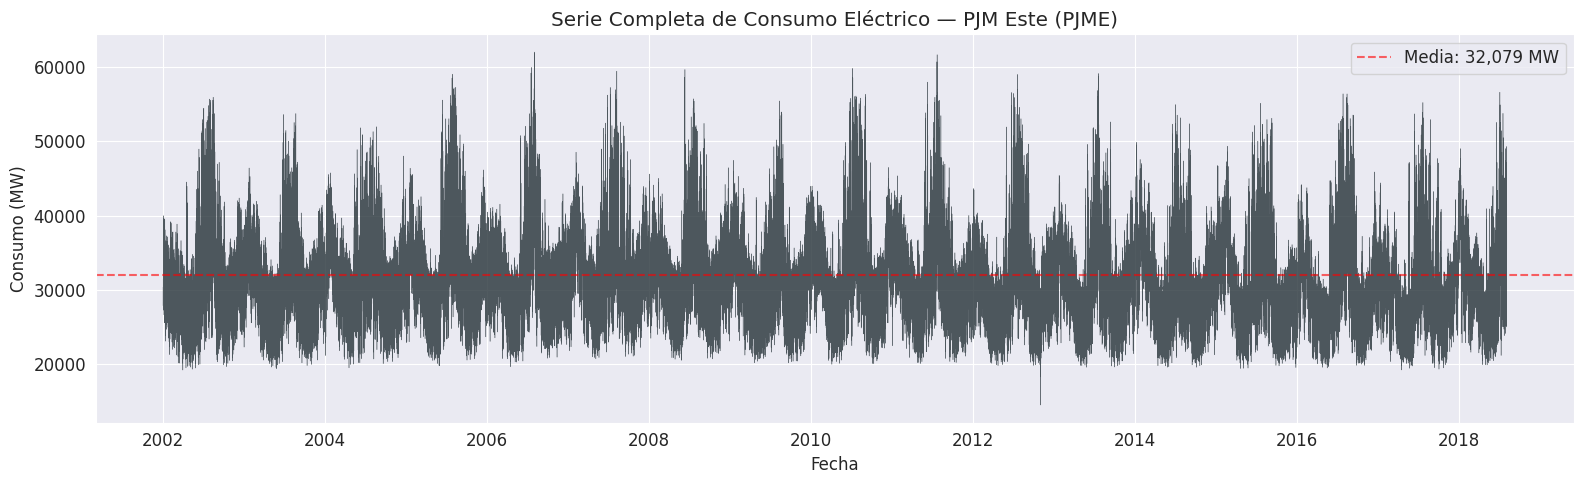

Estadísticas de consumo:
  Mínimo: 14,544 MW | Máximo: 62,009 MW | Media: 32,079 MW


In [ ]:
# ============================================================
# 📈 Visualización de la serie completa de consumo
# ============================================================
serie = df_pjm['MW']

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(serie.index, serie.values, linewidth=0.3, color=COLORS['actual'], alpha=0.8)
ax.axhline(y=serie.mean(), color='red', linestyle='--', alpha=0.6,
           label=f'Media: {serie.mean():,.0f} MW')
ax.set_xlabel('Fecha')
ax.set_ylabel('Consumo (MW)')
ax.set_title('Serie Completa de Consumo Eléctrico — PJM Este (PJME)')
ax.legend()
plt.tight_layout()
plt.show()

print('Estadísticas de consumo:')
print(f'  Mínimo: {serie.min():,.0f} MW | Máximo: {serie.max():,.0f} MW | Media: {serie.mean():,.0f} MW')

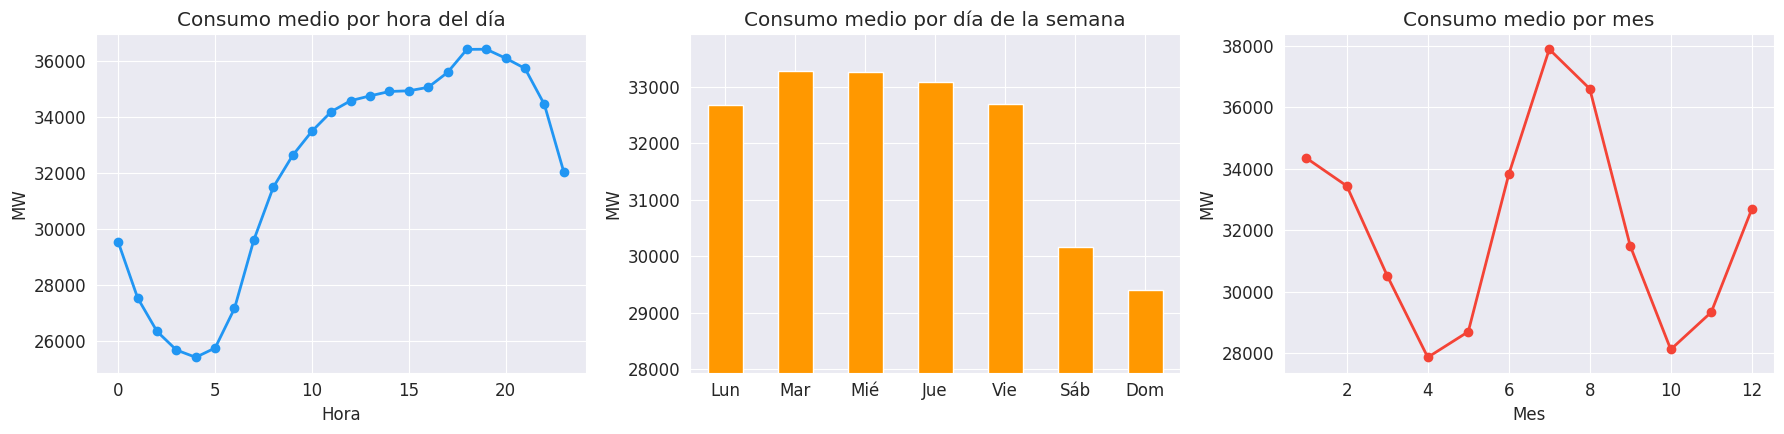

✅ Se observan tres ciclos: diario (día/noche), semanal (laborable vs fin de semana) y anual (picos en invierno y verano).


In [ ]:
# ============================================================
# 🔎 Patrones de consumo: hora del día, día de la semana y mes
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

serie.groupby(serie.index.hour).mean().plot(ax=axes[0], color=COLORS['lstm'], linewidth=2, marker='o')
axes[0].set_title('Consumo medio por hora del día')
axes[0].set_xlabel('Hora'); axes[0].set_ylabel('MW')

dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
by_dow = serie.groupby(serie.index.dayofweek).mean()
by_dow.plot(ax=axes[1], kind='bar', color=COLORS['gru'], edgecolor='white')
axes[1].set_ylim(by_dow.min() * 0.95, by_dow.max() * 1.02)   # zoom para ver la diferencia
axes[1].set_xticklabels(dias, rotation=0)
axes[1].set_title('Consumo medio por día de la semana')
axes[1].set_xlabel(''); axes[1].set_ylabel('MW')

serie.groupby(serie.index.month).mean().plot(ax=axes[2], color=COLORS['rnn'], linewidth=2, marker='o')
axes[2].set_title('Consumo medio por mes')
axes[2].set_xlabel('Mes'); axes[2].set_ylabel('MW')

plt.tight_layout()
plt.show()

print('✅ Se observan tres ciclos: diario (día/noche), semanal (laborable vs fin de semana) y anual (picos en invierno y verano).')

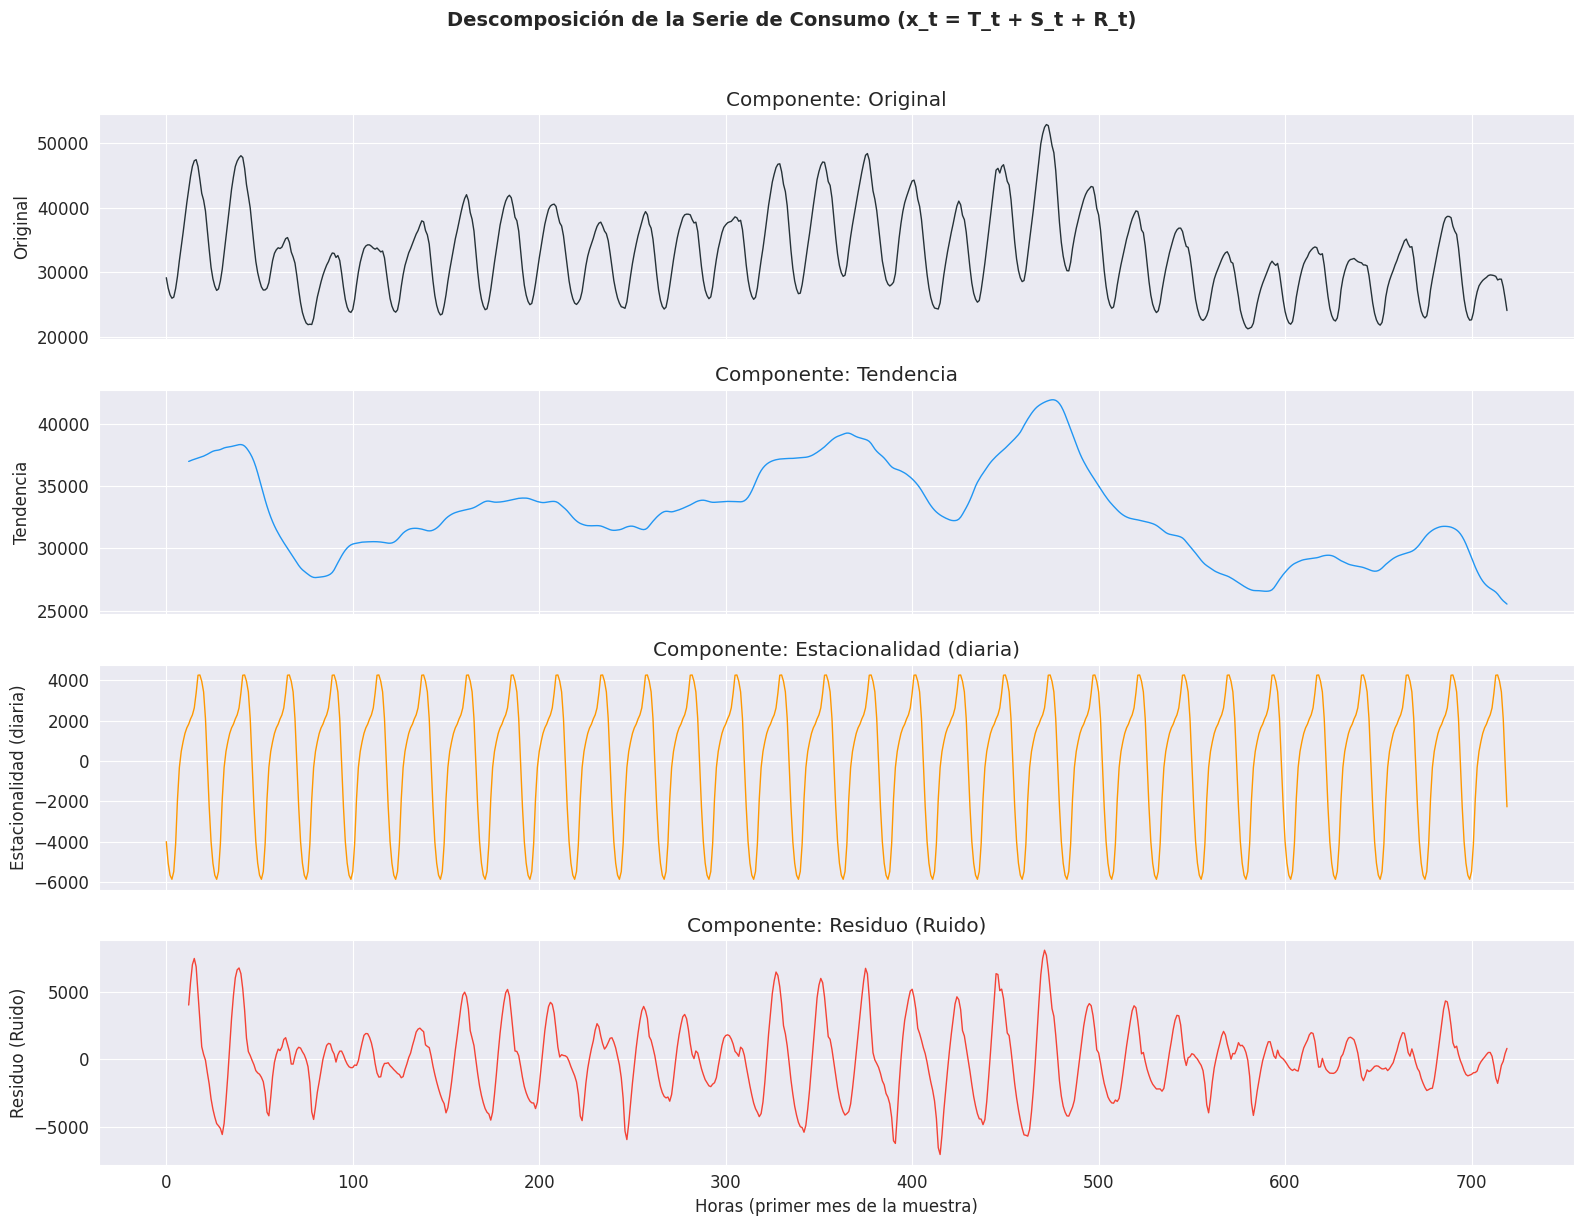

✅ Se observa claramente:
   • Tendencia: variación lenta (semanas/estaciones) y efecto de fin de semana
   • Estacionalidad diaria: ciclo de ~24h con valle nocturno y pico vespertino
   • Residuo: variaciones por clima, eventos y ruido


In [ ]:
# ============================================================
# 📊 Descomposición estacional
# ============================================================
from statsmodels.tsa.seasonal import seasonal_decompose

# Tomar el último año de datos horarios para la descomposición
sample_year = serie.iloc[-8760:].values  # 1 año ≈ 8760 horas

decomposition = seasonal_decompose(
    sample_year,
    model='additive',
    period=24  # Período diario (24 horas)
)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
components = [
    ('Original', sample_year, COLORS['actual']),
    ('Tendencia', decomposition.trend, COLORS['lstm']),
    ('Estacionalidad (diaria)', decomposition.seasonal, COLORS['gru']),
    ('Residuo (Ruido)', decomposition.resid, COLORS['rnn'])
]

for ax, (name, data, color) in zip(axes, components):
    ax.plot(data[:720], color=color, linewidth=1)  # Primer mes
    ax.set_ylabel(name)
    ax.set_title(f'Componente: {name}')

axes[-1].set_xlabel('Horas (primer mes de la muestra)')
fig.suptitle('Descomposición de la Serie de Consumo (x_t = T_t + S_t + R_t)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('✅ Se observa claramente:')
print('   • Tendencia: variación lenta (semanas/estaciones) y efecto de fin de semana')
print('   • Estacionalidad diaria: ciclo de ~24h con valle nocturno y pico vespertino')
print('   • Residuo: variaciones por clima, eventos y ruido')

### 🔧 Preprocesamiento — Las 3 Reglas de Oro

1. **Serie regular y limpia**: En el dataset PJM los datos ya son horarios, así que **no hizo falta submuestrear** (en otras series, como Jena, sí). Lo que sí se hizo fue ordenar, promediar los 4 timestamps duplicados (cambio de horario de verano) e interpolar las 30 horas faltantes (0.02 % de la serie): una ventana deslizante asume que *cada fila es exactamente una hora después de la anterior*.

2. **Split cronológico (NUNCA aleatorio)**: Se usó el primer 80 % para entrenamiento (116,313 h; 2002-01-01 → 2015-04-09) y el 20 % final para test (29,079 h; 2015-04-09 → 2018-08-03). Mezclar aleatoriamente crearía **fuga de datos temporal** (data leakage).

3. **Normalización con fit SOLO en train**: El `MinMaxScaler` aprendió los rangos solo de los datos de entrenamiento. En train el rango normalizado es [0, 1]; en test quedó en [0.099, 0.886], dentro de [0, 1], sin valores extrapolados.

```
INCORRECTO:  scaler.fit_transform(todo_el_dataset)  ← ¡Data leakage!
CORRECTO:    scaler.fit(train); scaler.transform(train); scaler.transform(test)
```

Con una ventana de 72 horas (3 días) y horizonte de 1 hora se obtuvieron 116,241 ventanas de entrenamiento y 29,007 de test, con forma `(muestras, 72, 1)`.

Datos horarios: 145,392 (cada hora)

Split cronológico:
  Train: 116,313 horas (13.3 años) | 2002-01-01 → 2015-04-09
  Test:  29,079 horas (3.3 años) | 2015-04-09 → 2018-08-03

Rango normalizado (train): [0.000, 1.000]
Rango normalizado (test):  [0.099, 0.886]  ← puede salirse de [0,1]: es normal


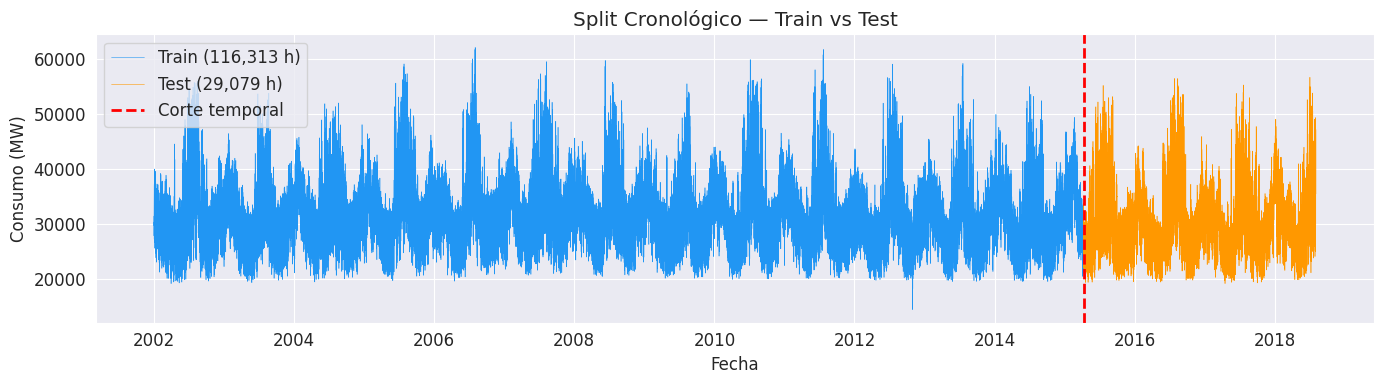

In [ ]:
# ============================================================
# 🔧 Preprocesamiento
# ============================================================

# 1. La serie ya es horaria y regular (sin submuestreo)
values = serie.values.astype('float32')
print(f'Datos horarios: {len(values):,} (cada hora)')

# 2. Split cronológico 80/20
split_idx = int(len(values) * 0.8)
train_data = values[:split_idx]
test_data = values[split_idx:]

print(f'\nSplit cronológico:')
print(f'  Train: {len(train_data):,} horas ({len(train_data)/(24*365.25):.1f} años) '
      f'| {serie.index[0].date()} → {serie.index[split_idx-1].date()}')
print(f'  Test:  {len(test_data):,} horas ({len(test_data)/(24*365.25):.1f} años) '
      f'| {serie.index[split_idx].date()} → {serie.index[-1].date()}')

# 3. Normalización — fit SOLO en train
scaler_uni = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler_uni.fit_transform(train_data.reshape(-1, 1)).flatten()
test_scaled = scaler_uni.transform(test_data.reshape(-1, 1)).flatten()

print(f'\nRango normalizado (train): [{train_scaled.min():.3f}, {train_scaled.max():.3f}]')
print(f'Rango normalizado (test):  [{test_scaled.min():.3f}, {test_scaled.max():.3f}]  '
      f'← puede salirse de [0,1]: es normal')

# Visualizar split
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(serie.index[:split_idx], train_data, color=COLORS['lstm'],
        label=f'Train ({len(train_data):,} h)', linewidth=0.4)
ax.plot(serie.index[split_idx:], test_data, color=COLORS['gru'],
        label=f'Test ({len(test_data):,} h)', linewidth=0.4)
ax.axvline(x=serie.index[split_idx], color='red', linestyle='--', linewidth=2, label='Corte temporal')
ax.set_xlabel('Fecha')
ax.set_ylabel('Consumo (MW)')
ax.set_title('Split Cronológico — Train vs Test')
ax.legend()
plt.tight_layout()
plt.show()

Ventana: 72 horas (3 días) → Predecir: 1 hora

Shapes:
  X_train: (116241, 72, 1)  (muestras, pasos, features)
  y_train: (116241,)
  X_test:  (29007, 72, 1)
  y_test:  (29007,)


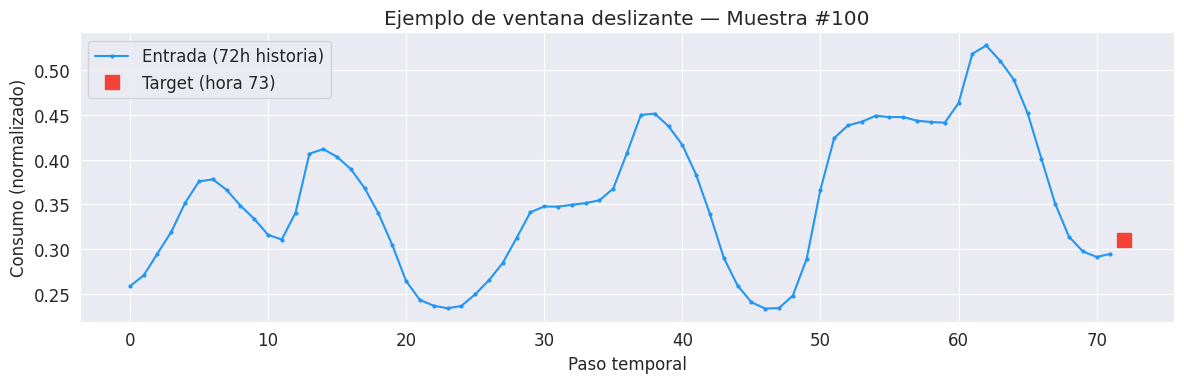

In [ ]:
# ============================================================
# 🪟 Creación de ventanas deslizantes
# ============================================================
WINDOW_SIZE = 72   # 72 horas = 3 días de historia
HORIZON = 1        # Predecir 1 hora adelante

X_train_uni, y_train_uni = create_sequences(train_scaled, WINDOW_SIZE, HORIZON)
X_test_uni, y_test_uni = create_sequences(test_scaled, WINDOW_SIZE, HORIZON)

print(f'Ventana: {WINDOW_SIZE} horas (3 días) → Predecir: {HORIZON} hora')
print(f'\nShapes:')
print(f'  X_train: {X_train_uni.shape}  (muestras, pasos, features)')
print(f'  y_train: {y_train_uni.shape}')
print(f'  X_test:  {X_test_uni.shape}')
print(f'  y_test:  {y_test_uni.shape}')

# Visualizar una ventana de ejemplo
fig, ax = plt.subplots(figsize=(12, 4))
sample_idx = 100
window = X_train_uni[sample_idx, :, 0]
target = y_train_uni[sample_idx]
ax.plot(range(WINDOW_SIZE), window, 'o-', color=COLORS['lstm'],
        markersize=2, label=f'Entrada ({WINDOW_SIZE}h historia)')
ax.plot(WINDOW_SIZE, target, 's', color=COLORS['rnn'],
        markersize=10, label=f'Target (hora {WINDOW_SIZE+1})')
ax.set_xlabel('Paso temporal')
ax.set_ylabel('Consumo (normalizado)')
ax.set_title(f'Ejemplo de ventana deslizante — Muestra #{sample_idx}')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 🏗️ Modelo LSTM Simple
# ============================================================
tf.random.set_seed(42)

model_lstm_basic = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 1)),
    layers.LSTM(64, name='lstm_64'),
    layers.Dropout(0.2, name='dropout'),
    layers.Dense(1, name='salida')
], name='LSTM_Basico')

model_lstm_basic.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model_lstm_basic.summary()

# Contar parámetros
total_params = model_lstm_basic.count_params()
trainable_params = count_trainable(model_lstm_basic)
print(f'\n📊 Parámetros totales: {total_params:,}')
print(f'   Parámetros entrenables: {trainable_params:,}')

Model: "LSTM_Basico"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_64 (LSTM)                  │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)


📊 Parámetros totales: 16,961
   Parámetros entrenables: 16,961


Entrenando LSTM básico...
Epoch 1/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0058 - mae: 0.0554 - val_loss: 0.0014 - val_mae: 0.0290 - learning_rate: 0.0010
Epoch 2/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0015 - mae: 0.0302 - val_loss: 4.2949e-04 - val_mae: 0.0158 - learning_rate: 0.0010
Epoch 3/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 8.1884e-04 - mae: 0.0220 - val_loss: 2.9382e-04 - val_mae: 0.0131 - learning_rate: 0.0010
Epoch 4/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 5.7370e-04 - mae: 0.0183 - val_loss: 2.2288e-04 - val_mae: 0.0114 - learning_rate: 0.0010
Epoch 5/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 4.1889e-04 - mae: 0.0154 - val_loss: 1.5664e-04 - val_mae: 0.0096 - learning_rate: 0.0010
Epoch 6/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 3.1840e-04 - mae: 0.0134 - val_loss: 1.4209e-04 - val_mae: 0.0094 - learning_rate: 0.0010
Epoch 7/30
772/772 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 2.7629e-04 - mae: 0.0125 

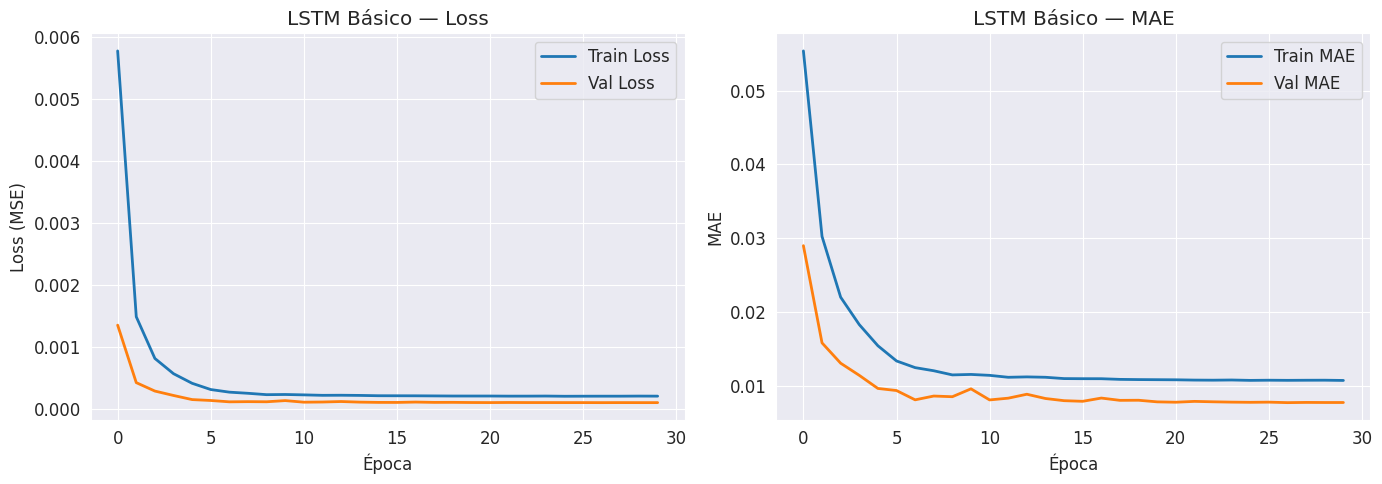

In [ ]:
# ============================================================
# 🚀 Entrenamiento del LSTM
# ============================================================
EPOCHS = 30
BATCH_SIZE = 128   # ~100K ventanas de entrenamiento: un batch mayor acelera cada época

cb_list = [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True,
                            monitor='val_loss', verbose=1),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3,
                                monitor='val_loss', verbose=1)
]

# Nota: validation_split toma el ÚLTIMO 15% de las ventanas de train (sin barajar),
# por lo que la validación también es cronológica.
print('Entrenando LSTM básico...')
t0 = time.time()
history_basic = model_lstm_basic.fit(
    X_train_uni, y_train_uni,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    callbacks=cb_list,
    verbose=1
)
time_lstm_basic = time.time() - t0
print(f'\n⏱️ Tiempo de entrenamiento: {time_lstm_basic:.1f} segundos')

plot_training_history(history_basic, 'LSTM Básico')

In [ ]:
# ============================================================
# 📏 Evaluación vs Baselines (Naive y Naive estacional)
# ============================================================

# Predicciones del modelo
y_pred_basic = model_lstm_basic.predict(X_test_uni, batch_size=1024, verbose=0).flatten()

# Baseline 1 — Naive: repetir el último valor conocido de la ventana (hace 1 h)
y_naive = X_test_uni[:, -1, 0]

# Baseline 2 — Naive estacional: repetir el valor de la MISMA hora del día anterior
# (el target está en la posición WINDOW_SIZE; 24 h antes es X[:, -24])
y_snaive = X_test_uni[:, -24, 0]

# Desnormalizar para métricas interpretables (MW)
inverse = lambda a: scaler_uni.inverse_transform(a.reshape(-1, 1)).flatten()
y_test_real = inverse(y_test_uni)
y_pred_real = inverse(y_pred_basic)
y_naive_real = inverse(y_naive)
y_snaive_real = inverse(y_snaive)

# Métricas
metrics_lstm = evaluate_forecast(y_test_real, y_pred_real)
metrics_naive = evaluate_forecast(y_test_real, y_naive_real)
metrics_snaive = evaluate_forecast(y_test_real, y_snaive_real)

print('=' * 66)
print('COMPARACIÓN: LSTM vs Baselines')
print('=' * 66)
print(f'{"":<18} {"MAE (MW)":<15} {"RMSE (MW)":<15} {"MAPE (%)":<15}')
print('-' * 66)
print(f'{"Naive (t-1h)":<18} {metrics_naive["MAE"]:<15.1f} {metrics_naive["RMSE"]:<15.1f} {metrics_naive["MAPE"]:<15.2f}')
print(f'{"Naive est. (t-24h)":<18} {metrics_snaive["MAE"]:<15.1f} {metrics_snaive["RMSE"]:<15.1f} {metrics_snaive["MAPE"]:<15.2f}')
print(f'{"LSTM":<18} {metrics_lstm["MAE"]:<15.1f} {metrics_lstm["RMSE"]:<15.1f} {metrics_lstm["MAPE"]:<15.2f}')
print('-' * 66)

imp_naive = (1 - metrics_lstm['MAE'] / metrics_naive['MAE']) * 100
imp_snaive = (1 - metrics_lstm['MAE'] / metrics_snaive['MAE']) * 100
print(f'\nMAE del LSTM vs Naive:           {imp_naive:+.1f}%  ({"mejora" if imp_naive > 0 else "NO mejora"})')
print(f'MAE del LSTM vs Naive estacional: {imp_snaive:+.1f}%  ({"mejora" if imp_snaive > 0 else "NO mejora"})')

COMPARACIÓN: LSTM vs Baselines
                   MAE (MW)        RMSE (MW)       MAPE (%)       
------------------------------------------------------------------
Naive (t-1h)       1070.5          1374.4          3.48           
Naive est. (t-24h) 2182.8          3007.6          6.92           
LSTM               344.2           456.0           1.12           
------------------------------------------------------------------

MAE del LSTM vs Naive:           +67.8%  (mejora)
MAE del LSTM vs Naive estacional: +84.2%  (mejora)


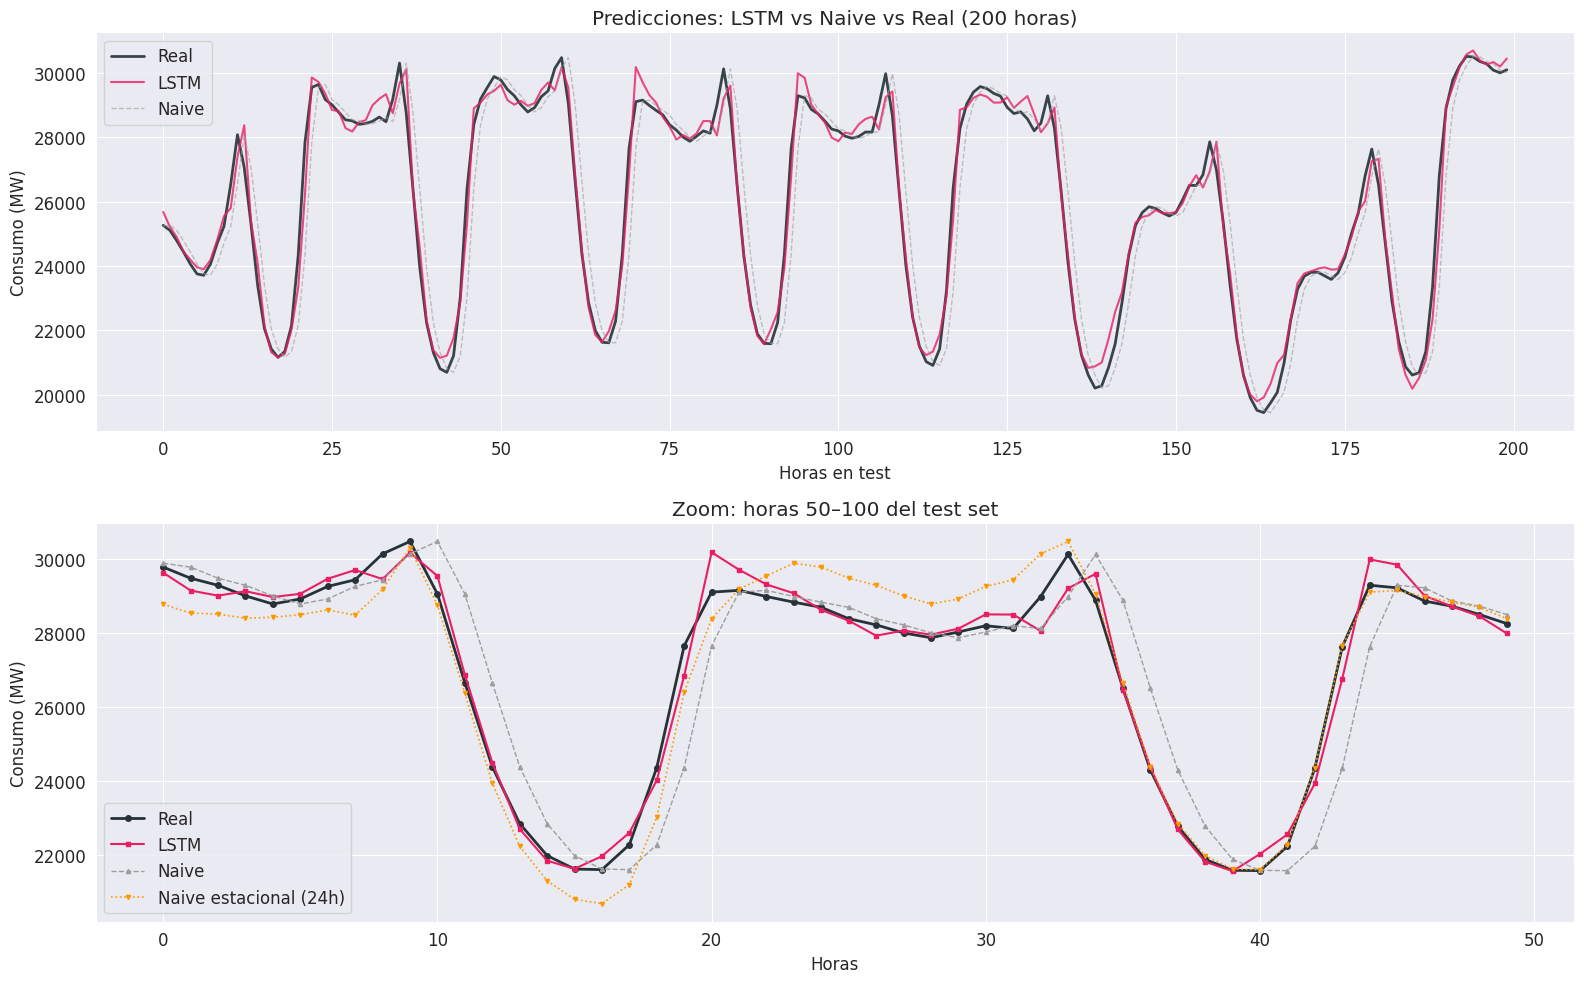

In [ ]:
# ============================================================
# 📊 Visualización de predicciones
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Subplot 1: Primeras 200 horas del test
n_show = 200
axes[0].plot(y_test_real[:n_show], color=COLORS['actual'],
             linewidth=2, label='Real', alpha=0.9)
axes[0].plot(y_pred_real[:n_show], color=COLORS['pred'],
             linewidth=1.5, label='LSTM', alpha=0.8)
axes[0].plot(y_naive_real[:n_show], color=COLORS['naive'],
             linewidth=1, linestyle='--', label='Naive', alpha=0.6)
axes[0].set_ylabel('Consumo (MW)')
axes[0].set_title('Predicciones: LSTM vs Naive vs Real (200 horas)')
axes[0].legend()
axes[0].set_xlabel('Horas en test')

# Subplot 2: Zoom en 50 horas (incluye el naive estacional)
n_zoom = 50
start = 50
axes[1].plot(range(n_zoom), y_test_real[start:start+n_zoom],
             'o-', color=COLORS['actual'], linewidth=2,
             markersize=4, label='Real')
axes[1].plot(range(n_zoom), y_pred_real[start:start+n_zoom],
             's-', color=COLORS['pred'], linewidth=1.5,
             markersize=3, label='LSTM')
axes[1].plot(range(n_zoom), y_naive_real[start:start+n_zoom],
             '^--', color=COLORS['naive'], linewidth=1,
             markersize=3, label='Naive')
axes[1].plot(range(n_zoom), y_snaive_real[start:start+n_zoom],
             'v:', color=COLORS['gru'], linewidth=1.2,
             markersize=3, label='Naive estacional (24h)')
axes[1].set_ylabel('Consumo (MW)')
axes[1].set_xlabel('Horas')
axes[1].set_title(f'Zoom: horas {start}–{start+n_zoom} del test set')
axes[1].legend()

plt.tight_layout()
plt.show()

### 💡 Resultados y conclusiones del Ejercicio 1

**Resultados en el conjunto de test (29,007 horas, 2015-04 → 2018-08):**

| Modelo | MAE (MW) | RMSE (MW) | MAPE (%) |
|---|---|---|---|
| Naive (t-1 h) | 1,070.5 | 1,374.4 | 3.48 |
| Naive estacional (t-24 h) | 2,182.8 | 3,007.6 | 6.92 |
| **LSTM (64 unidades, 16,961 parámetros)** | **344.2** | **456.0** | **1.12** |

El LSTM redujo el MAE un **67.8 %** frente al naive y un **84.2 %** frente al naive estacional. Su error medio (344 MW) equivale a ≈1.1 % del consumo medio de la serie (32,079 MW). El entrenamiento tomó 196.9 s (≈3.3 min).

**Conclusiones:**

1. **El LSTM supera con claridad a ambos baselines.** A 1 hora de horizonte el consumo cambia suavemente, así que el *naive* (repetir la última hora) es un rival razonable, y aun así el LSTM lo mejora en MAE, RMSE y MAPE. En las gráficas de predicción el naive aparece como una copia retrasada una hora de la serie real, mientras que el LSTM sigue el valle nocturno y los picos sin ese retraso.
2. **El naive estacional (t-24 h) resultó el peor, no el más exigente.** A horizonte de 1 hora, la inercia (el valor de hace una hora) aporta más información que el ciclo diario: su MAE fue el doble que el del naive simple (2,183 vs 1,071 MW) porque se equivoca cuando el perfil de un día difiere del anterior (en el zoom de las gráficas se observan desviaciones de ≈1,000 MW o más). Su utilidad como vara de comparación aumenta con horizontes más largos, que no se evaluaron aquí.
3. **El entrenamiento convergió de forma estable.** Se completaron las 30 épocas (EarlyStopping no llegó a detener el entrenamiento) y se restauraron los pesos de la mejor época (27, `val_loss` = 1.08e-4, `val_mae` = 0.0077 en escala normalizada). `ReduceLROnPlateau` bajó la tasa de aprendizaje desde 1e-3 hasta ≈4e-6. La pérdida de validación quedó por debajo de la de entrenamiento (1.08e-4 vs 2.1e-4), lo que es coherente con que el *Dropout* solo actúa en entrenamiento; no hay señales de sobreajuste.
4. **La preparación de datos fue determinante:** serie regular (se corrigieron 4 duplicados y 30 huecos antes de crear ventanas), split cronológico y normalización con `fit` solo en train. El modelo generaliza a 3.3 años posteriores a los que vio en entrenamiento, con un MAE de ≈1.1 %.
5. **Limitación:** el modelo usa solo el historial de consumo. Variables como temperatura, hora o día de la semana no se incorporaron en este ejercicio, y son el paso natural para mejorarlo; el Ejercicio 2 evalúa ese efecto con otro dataset (que sí trae variables climáticas), donde las variables adicionales redujeron el MAE entre 17.6 % y 18.2 %.

---

## 🚲 Ejercicio 2 (Intermedio): Pronóstico Multivariado de Demanda de Bicicletas — LSTM vs GRU

**Objetivo:** Comparar LSTM y GRU en pronóstico multivariado, usando variables climáticas y de calendario para predecir la **demanda horaria de bicicletas compartidas** en Seúl.

**Dataset:** [Seoul Bike Sharing Demand](https://www.kaggle.com/datasets/saurabhshahane/seoul-bike-sharing-demand-prediction) — Un año de registros horarios (8,760 filas, 2017-12-01 → 2018-11-30) con el número de bicicletas alquiladas (`Rented Bike Count`) y variables como temperatura, humedad, viento, radiación solar, lluvia, nieve, estación y feriados.

**Hipótesis:** Las variables correlacionadas (temperatura, radiación solar, lluvia) y la hora del día deberían mejorar la predicción respecto al enfoque univariado (solo historial de demanda). *Resultado: la hipótesis se confirmó (ver conclusiones al final del ejercicio).*

**Adicionalmente:** Se experimentó con diferentes tamaños de ventana (24, 72 y 168 horas) para encontrar el *sweet spot*.

**Tarea:** Forecasting multivariado (many-to-one) — predecir la demanda de la próxima hora.

> ⚠️ **Nota:** este dataset es mucho más pequeño que PJM (1 año vs ~16 años). El conjunto de test cubrió los últimos 73 días (2018-09-19 → 2018-11-30), una época **que el modelo no vio en entrenamiento**: el train llega hasta 2018-09-18 y el dataset empieza en diciembre, así que octubre y noviembre solo aparecen en test.

In [ ]:
# ============================================================
# 📥 Descarga, limpieza e ingeniería de variables — Seoul Bike
# ============================================================
SEOUL_HANDLE = 'saurabhshahane/seoul-bike-sharing-demand-prediction'
SEOUL_FILE = 'SeoulBikeData.csv'

csv_seoul = load_kaggle_file(SEOUL_HANDLE, SEOUL_FILE)
# El CSV trae el símbolo "°" (no es UTF-8) -> encoding latin1
df_seoul_raw = pd.read_csv(csv_seoul, encoding='latin1')
assert df_seoul_raw.shape[1] == 14, f'Se esperaban 14 columnas y hay {df_seoul_raw.shape[1]}'

# Renombrar por POSICIÓN (los nombres originales tienen símbolos y espacios)
df_seoul_raw.columns = ['date', 'bikes', 'hour', 'temp', 'humidity', 'wind',
                        'visibility', 'dew_point', 'solar', 'rain', 'snow',
                        'season', 'holiday', 'functioning']

df_seoul = df_seoul_raw.copy()

# Índice temporal = fecha (dd/mm/aaaa) + hora
df_seoul['datetime'] = (pd.to_datetime(df_seoul['date'], format='%d/%m/%Y')
                        + pd.to_timedelta(df_seoul['hour'], unit='h'))
df_seoul = df_seoul.sort_values('datetime').set_index('datetime')

# Verificar que la serie sea horaria y regular
gaps = df_seoul.index.to_series().diff().dropna()
print(f'Filas: {len(df_seoul):,} | Rango: {df_seoul.index[0]} → {df_seoul.index[-1]}')
print(f'¿Serie horaria regular? {"✅ Sí" if (gaps == pd.Timedelta("1h")).all() else "⚠️ No: hay huecos o duplicados"}')
print(f'Valores nulos totales: {int(df_seoul.isna().sum().sum())}')

# Variables binarias
df_seoul['holiday_flag'] = (df_seoul['holiday'] == 'Holiday').astype('float32')
df_seoul['functioning_flag'] = (df_seoul['functioning'] == 'Yes').astype('float32')

# Hora del día como variable CÍCLICA: la hora 23 y la hora 0 están pegadas,
# pero numéricamente están lejos. Con seno/coseno el círculo se cierra.
df_seoul['hour_sin'] = np.sin(2 * np.pi * df_seoul['hour'] / 24).astype('float32')
df_seoul['hour_cos'] = np.cos(2 * np.pi * df_seoul['hour'] / 24).astype('float32')

n_off = int((df_seoul['functioning_flag'] == 0).sum())
print(f'\nHoras fuera de servicio (Functioning Day = No): {n_off} '
      f'({n_off/len(df_seoul)*100:.1f}%) → la demanda es 0 en esas horas')
print(f'Demanda: min {df_seoul["bikes"].min():,} | max {df_seoul["bikes"].max():,} | '
      f'media {df_seoul["bikes"].mean():,.0f} bicicletas/hora')

df_seoul.head()

100%|██████████| 126k/126k [00:00<00:00, 315kB/s]

Extracting files...
Filas: 8,760 | Rango: 2017-12-01 00:00:00 → 2018-11-30 23:00:00
¿Serie horaria regular? ✅ Sí
Valores nulos totales: 0

Horas fuera de servicio (Functioning Day = No): 295 (3.4%) → la demanda es 0 en esas horas
Demanda: min 0 | max 3,556 | media 705 bicicletas/hora


,date,bikes,hour,temp,humidity,wind,visibility,dew_point,solar,rain,snow,season,holiday,functioning,holiday_flag,functioning_flag,hour_sin,hour_cos
datetime,,,,,,,,,,,,,,,,,,
2017-12-01 00:00:00,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,0.0,1.0,0.000000,1.000000
2017-12-01 01:00:00,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,0.0,1.0,0.258819,0.965926
2017-12-01 02:00:00,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,0.0,1.0,0.500000,0.866025
2017-12-01 03:00:00,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,0.0,1.0,0.707107,0.707107
2017-12-01 04:00:00,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,0.0,1.0,0.866025,0.500000


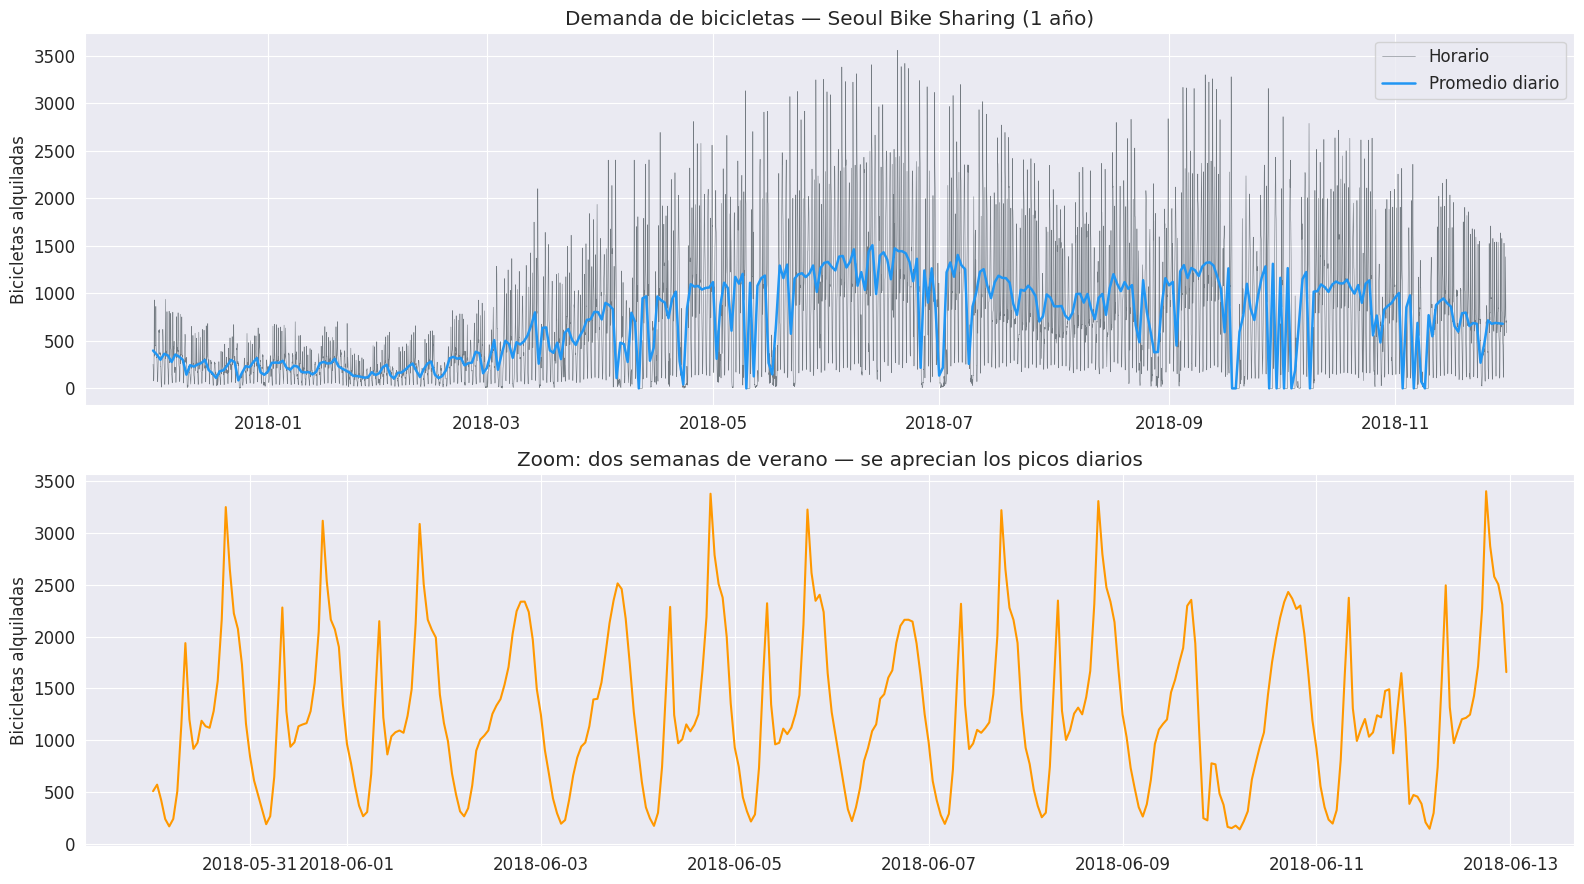

In [ ]:
# ============================================================
# 📈 Visualización de la demanda
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# Serie completa + promedio diario
axes[0].plot(df_seoul.index, df_seoul['bikes'], linewidth=0.4,
             color=COLORS['actual'], alpha=0.6, label='Horario')
daily = df_seoul['bikes'].resample('D').mean()
axes[0].plot(daily.index, daily.values, color=COLORS['lstm'],
             linewidth=1.8, label='Promedio diario')
axes[0].set_ylabel('Bicicletas alquiladas')
axes[0].set_title('Demanda de bicicletas — Seoul Bike Sharing (1 año)')
axes[0].legend()

# Zoom de dos semanas: ciclo diario y semanal
two_weeks = df_seoul['bikes'].iloc[24 * 180: 24 * 194]
axes[1].plot(two_weeks.index, two_weeks.values, color=COLORS['gru'], linewidth=1.5)
axes[1].set_ylabel('Bicicletas alquiladas')
axes[1].set_title('Zoom: dos semanas de verano — se aprecian los picos diarios')

plt.tight_layout()
plt.show()

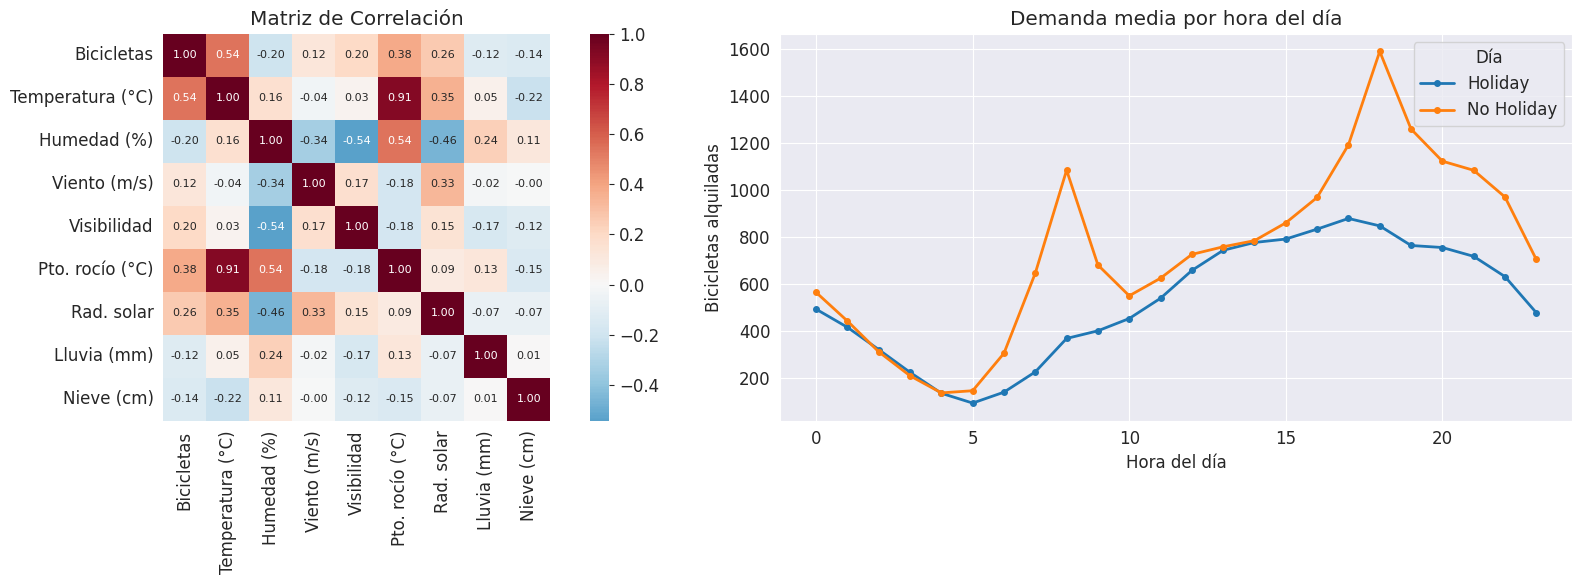

📊 Correlación de cada variable con la demanda de bicicletas:
   Temperatura (°C)   +0.539
   Pto. rocío (°C)    +0.380
   Rad. solar         +0.262
   Humedad (%)        -0.200
   Visibilidad        +0.199
   Nieve (cm)         -0.142
   Lluvia (mm)        -0.123
   Viento (m/s)       +0.121


In [ ]:
# ============================================================
# 🔗 Análisis de correlación y perfil horario
# ============================================================
num_cols = ['bikes', 'temp', 'humidity', 'wind', 'visibility', 'dew_point', 'solar', 'rain', 'snow']
num_names = ['Bicicletas', 'Temperatura (°C)', 'Humedad (%)', 'Viento (m/s)',
             'Visibilidad', 'Pto. rocío (°C)', 'Rad. solar', 'Lluvia (mm)', 'Nieve (cm)']

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Heatmap de correlación
corr_matrix = df_seoul[num_cols].corr().fillna(0)   # fillna: variable constante -> corr indefinida
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0,
            xticklabels=num_names, yticklabels=num_names,
            ax=axes[0], fmt='.2f', square=True, annot_kws={'size': 8})
axes[0].set_title('Matriz de Correlación')

# Perfil horario (solo horas en servicio), feriado vs no feriado
active = df_seoul[df_seoul['functioning_flag'] == 1]
profile = active.groupby(['holiday', 'hour'])['bikes'].mean().unstack(0)
profile.plot(ax=axes[1], linewidth=2, marker='o', markersize=4)
axes[1].set_title('Demanda media por hora del día')
axes[1].set_xlabel('Hora del día')
axes[1].set_ylabel('Bicicletas alquiladas')
axes[1].legend(title='Día')

plt.tight_layout()
plt.show()

print('📊 Correlación de cada variable con la demanda de bicicletas:')
for col, name in sorted(zip(num_cols[1:], num_names[1:]),
                        key=lambda p: -abs(corr_matrix.loc['bikes', p[0]])):
    print(f'   {name:<18} {corr_matrix.loc["bikes", col]:+.3f}')

In [ ]:
# ============================================================
# 🔧 Preparación de datos multivariados
# ============================================================

# Variables de entrada. IMPORTANTE: la columna 0 es el TARGET (demanda)
selected_features = ['bikes', 'temp', 'humidity', 'wind', 'solar', 'rain',
                     'hour_sin', 'hour_cos', 'functioning_flag']
N_FEATURES = len(selected_features)

multi_data = df_seoul[selected_features].values.astype('float32')
print(f'Datos multivariados: {multi_data.shape} (horas, features)')

# Split cronológico 80/20
split_multi = int(len(multi_data) * 0.8)
train_multi = multi_data[:split_multi]
test_multi = multi_data[split_multi:]
print(f'Train: {len(train_multi):,} h ({df_seoul.index[0].date()} → {df_seoul.index[split_multi-1].date()})')
print(f'Test:  {len(test_multi):,} h ({df_seoul.index[split_multi].date()} → {df_seoul.index[-1].date()})')

# Normalizar CADA feature — fit solo en train
scaler_multi = MinMaxScaler()
train_multi_scaled = scaler_multi.fit_transform(train_multi)
test_multi_scaled = scaler_multi.transform(test_multi)

# Crear secuencias multivariadas (predecir solo la demanda = columna 0)
WINDOW_MULTI = 72
X_train_m, y_train_m = create_sequences(train_multi_scaled, WINDOW_MULTI, 1)
X_test_m, y_test_m = create_sequences(test_multi_scaled, WINDOW_MULTI, 1)

print(f'\nShapes multivariados:')
print(f'  X_train: {X_train_m.shape}  (muestras, {WINDOW_MULTI} pasos, {N_FEATURES} features)')
print(f'  y_train: {y_train_m.shape}  (predecir solo la demanda)')
print(f'  X_test:  {X_test_m.shape}')
print(f'  y_test:  {y_test_m.shape}')

# Versión UNIVARIADA (solo historial de demanda) para usar como referencia.
# Es simplemente la columna 0 de X; el target es exactamente el mismo.
X_train_u = np.ascontiguousarray(X_train_m[:, :, :1])
X_test_u = np.ascontiguousarray(X_test_m[:, :, :1])

# Parámetros del scaler del target para desnormalizar
bikes_min = scaler_multi.data_min_[0]
bikes_max = scaler_multi.data_max_[0]
print(f'\nRango de demanda (train): [{bikes_min:.0f}, {bikes_max:.0f}] bicicletas/hora')

def denorm_bikes(values):
    return values * (bikes_max - bikes_min) + bikes_min

Datos multivariados: (8760, 9) (horas, features)
Train: 7,008 h (2017-12-01 → 2018-09-18)
Test:  1,752 h (2018-09-19 → 2018-11-30)

Shapes multivariados:
  X_train: (6936, 72, 9)  (muestras, 72 pasos, 9 features)
  y_train: (6936,)  (predecir solo la demanda)
  X_test:  (1680, 72, 9)
  y_test:  (1680,)

Rango de demanda (train): [0, 3556] bicicletas/hora


In [ ]:
# ============================================================
# 🏗️ Referencia: LSTM univariado (solo historial de demanda)
# ============================================================
EPOCHS = 30
BATCH_SIZE = 32   # dataset pequeño (~7K ventanas) -> batch pequeño

cb_factory = lambda: [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

tf.random.set_seed(42)
model_lstm_uni = models.Sequential([
    layers.Input(shape=(WINDOW_MULTI, 1)),
    layers.LSTM(64, name='lstm_64'),
    layers.Dropout(0.2, name='dropout'),
    layers.Dense(1, name='salida')
], name='LSTM_Univariado_Bikes')
model_lstm_uni.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('⚪ Entrenando LSTM univariado (referencia)...')
t0 = time.time()
hist_lstm_uni = model_lstm_uni.fit(
    X_train_u, y_train_m,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_lstm_uni = time.time() - t0
params_lstm_uni = model_lstm_uni.count_params()
print(f'   ⏱️ {time_lstm_uni:.1f}s | Params: {params_lstm_uni:,} | '
      f'Mejor val_loss: {min(hist_lstm_uni.history["val_loss"]):.6f}')

⚪ Entrenando LSTM univariado (referencia)...
   ⏱️ 45.2s | Params: 16,961 | Mejor val_loss: 0.002498


In [ ]:
# ============================================================
# 🏗️ Modelo LSTM Stacked (apilado) — Multivariado
# ============================================================
tf.random.set_seed(42)

model_lstm_multi = models.Sequential([
    layers.Input(shape=(WINDOW_MULTI, N_FEATURES)),
    layers.LSTM(128, return_sequences=True, name='lstm_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.LSTM(64, name='lstm_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='LSTM_Stacked_Multi')

model_lstm_multi.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== LSTM Stacked Multivariado ===')
model_lstm_multi.summary()
lstm_params = model_lstm_multi.count_params()
print(f'\nTotal parámetros: {lstm_params:,}')

=== LSTM Stacked Multivariado ===


Model: "LSTM_Stacked_Multi"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_128 (LSTM)                 │ (None, 72, 128)        │        70,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 72, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_64 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,177 (477.25 KB)

 Trainable params: 122,177 (477.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 122,177


In [ ]:
# ============================================================
# 🏗️ Modelo GRU Stacked (apilado) — Multivariado
# ============================================================
tf.random.set_seed(42)

model_gru_multi = models.Sequential([
    layers.Input(shape=(WINDOW_MULTI, N_FEATURES)),
    layers.GRU(128, return_sequences=True, name='gru_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.GRU(64, name='gru_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='GRU_Stacked_Multi')

model_gru_multi.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== GRU Stacked Multivariado ===')
model_gru_multi.summary()
gru_params = model_gru_multi.count_params()
print(f'\nTotal parámetros: {gru_params:,}')
print(f'\n📊 Diferencia: LSTM tiene {lstm_params - gru_params:,} parámetros más que GRU')
print(f'   GRU es {(1 - gru_params/lstm_params)*100:.1f}% más ligero')

=== GRU Stacked Multivariado ===


Model: "GRU_Stacked_Multi"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_128 (GRU)                   │ (None, 72, 128)        │        53,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 72, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_64 (GRU)                    │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92,737 (362.25 KB)

 Trainable params: 92,737 (362.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 92,737

📊 Diferencia: LSTM tiene 29,440 parámetros más que GRU
   GRU es 24.1% más ligero


In [ ]:
# ============================================================
# 🚀 Entrenamiento de ambos modelos
# ============================================================

# Entrenar LSTM
print('🔵 Entrenando LSTM Stacked...')
t0 = time.time()
hist_lstm_m = model_lstm_multi.fit(
    X_train_m, y_train_m,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_lstm_m = time.time() - t0
print(f'   ⏱️ {time_lstm_m:.1f}s | Mejor val_loss: {min(hist_lstm_m.history["val_loss"]):.6f}')

# Entrenar GRU
print('🟠 Entrenando GRU Stacked...')
t0 = time.time()
hist_gru_m = model_gru_multi.fit(
    X_train_m, y_train_m,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_gru_m = time.time() - t0
print(f'   ⏱️ {time_gru_m:.1f}s | Mejor val_loss: {min(hist_gru_m.history["val_loss"]):.6f}')

faster = 'GRU' if time_gru_m < time_lstm_m else 'LSTM'
ratio = max(time_lstm_m, time_gru_m) / min(time_lstm_m, time_gru_m)
print(f'\n⚡ {faster} fue {ratio:.1f}x más rápido en esta corrida')

🔵 Entrenando LSTM Stacked...
   ⏱️ 69.2s | Mejor val_loss: 0.001617
🟠 Entrenando GRU Stacked...
   ⏱️ 66.5s | Mejor val_loss: 0.001687

⚡ GRU fue 1.0x más rápido en esta corrida


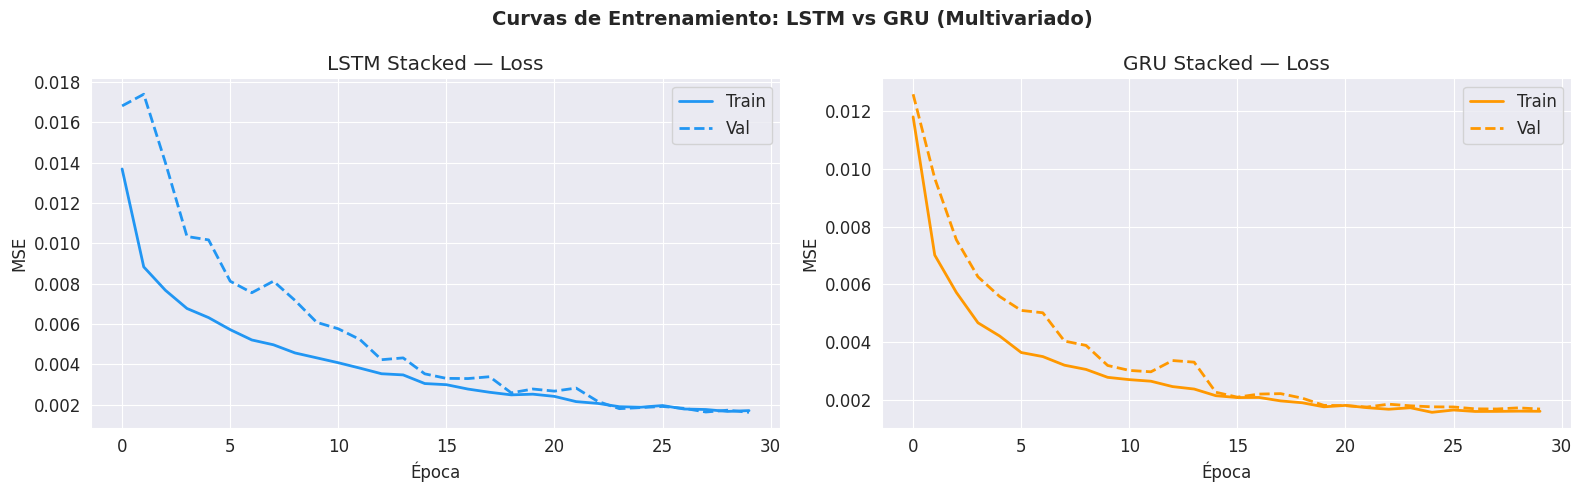

In [ ]:
# ============================================================
# 📉 Curvas de entrenamiento — LSTM vs GRU
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# LSTM
axes[0].plot(hist_lstm_m.history['loss'], color=COLORS['lstm'],
             label='Train', linewidth=2)
axes[0].plot(hist_lstm_m.history['val_loss'], color=COLORS['lstm'],
             linestyle='--', label='Val', linewidth=2)
axes[0].set_title('LSTM Stacked — Loss')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE')
axes[0].legend()

# GRU
axes[1].plot(hist_gru_m.history['loss'], color=COLORS['gru'],
             label='Train', linewidth=2)
axes[1].plot(hist_gru_m.history['val_loss'], color=COLORS['gru'],
             linestyle='--', label='Val', linewidth=2)
axes[1].set_title('GRU Stacked — Loss')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MSE')
axes[1].legend()

plt.suptitle('Curvas de Entrenamiento: LSTM vs GRU (Multivariado)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 📏 Comparación de predicciones: baselines, univariado y multivariado
# ============================================================

# Predicciones (escala normalizada)
pred_uni_m = model_lstm_uni.predict(X_test_u, verbose=0).flatten()
pred_lstm_m = model_lstm_multi.predict(X_test_m, verbose=0).flatten()
pred_gru_m = model_gru_multi.predict(X_test_m, verbose=0).flatten()

# Baselines: la demanda es la columna 0 de la ventana
naive_m = X_test_m[:, -1, 0]     # hace 1 h
snaive_m = X_test_m[:, -24, 0]   # misma hora del día anterior

# Desnormalizar (la demanda es la columna 0)
y_test_real_m = denorm_bikes(y_test_m)
pred_uni_real = denorm_bikes(pred_uni_m)
pred_lstm_real = denorm_bikes(pred_lstm_m)
pred_gru_real = denorm_bikes(pred_gru_m)
naive_real = denorm_bikes(naive_m)
snaive_real = denorm_bikes(snaive_m)

# Métricas (el MAPE es inestable con demandas cercanas a 0: usar MAE/RMSE)
rows = [
    ('Naive (t-1h)',        evaluate_forecast(y_test_real_m, naive_real),      None,            None),
    ('Naive est. (t-24h)',  evaluate_forecast(y_test_real_m, snaive_real),     None,            None),
    ('LSTM Univariado',     evaluate_forecast(y_test_real_m, pred_uni_real),   params_lstm_uni, time_lstm_uni),
    ('LSTM Stacked Multi',  evaluate_forecast(y_test_real_m, pred_lstm_real),  lstm_params,     time_lstm_m),
    ('GRU Stacked Multi',   evaluate_forecast(y_test_real_m, pred_gru_real),   gru_params,      time_gru_m),
]

print('=' * 84)
print('COMPARACIÓN — Demanda de bicicletas (test cronológico)')
print('=' * 84)
print(f'{"":<20} {"MAE (bicis)":<14} {"RMSE (bicis)":<14} {"Params":<12} {"Tiempo (s)":<12}')
print('-' * 84)
for name, m, p, t in rows:
    p_txt = f'{p:,}' if p else '—'
    t_txt = f'{t:.1f}' if t else '—'
    print(f'{name:<20} {m["MAE"]:<14.1f} {m["RMSE"]:<14.1f} {p_txt:<12} {t_txt:<12}')
print('-' * 84)

best_name = min(rows, key=lambda r: r[1]['MAE'])[0]
print(f'\n🏆 Menor MAE: {best_name}')

mae_uni = rows[2][1]['MAE']
for name, m, _, _ in rows[3:]:
    delta = (1 - m['MAE'] / mae_uni) * 100
    print(f'   {name} vs LSTM Univariado: {delta:+.1f}% de MAE')

COMPARACIÓN — Demanda de bicicletas (test cronológico)
                     MAE (bicis)    RMSE (bicis)   Params       Tiempo (s)  
------------------------------------------------------------------------------------
Naive (t-1h)         194.8          302.1          —            —           
Naive est. (t-24h)   392.7          656.9          —            —           
LSTM Univariado      117.7          176.7          16,961       45.2        
LSTM Stacked Multi   97.0           139.7          122,177      69.2        
GRU Stacked Multi    96.3           144.4          92,737       66.5        
------------------------------------------------------------------------------------

🏆 Menor MAE: GRU Stacked Multi
   LSTM Stacked Multi vs LSTM Univariado: +17.6% de MAE
   GRU Stacked Multi vs LSTM Univariado: +18.2% de MAE


Experimentando con diferentes tamaños de ventana (GRU) — evaluando sobre 1584 horas comunes...
  Ventana= 24h (1d) | MAE: 150.35 bicis | Tiempo: 26.1s | Params: 14,465
  Ventana= 72h (3d) | MAE: 141.05 bicis | Tiempo: 31.0s | Params: 14,465
  Ventana=168h (7d) | MAE: 144.12 bicis | Tiempo: 39.1s | Params: 14,465


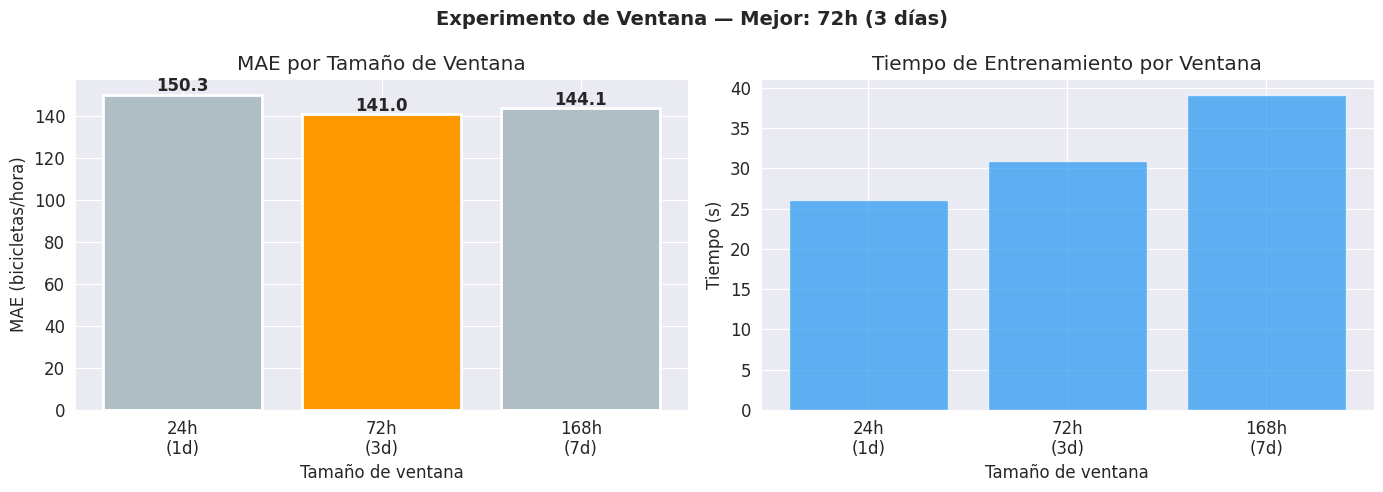

In [ ]:
# ============================================================
# 🔍 Experimento: Tamaño de ventana óptimo
# ============================================================
windows = [24, 72, 168]  # 1 día, 3 días, 1 semana
window_results = {}

# Cada ventana "consume" w horas iniciales del test, así que los test sets
# tienen tamaños distintos. Para comparar de forma justa, evaluamos todas las
# ventanas sobre los MISMOS targets (los últimos n_common).
n_common = len(test_multi_scaled) - max(windows)

print(f'Experimentando con diferentes tamaños de ventana (GRU) — evaluando sobre {n_common} horas comunes...')
for w in windows:
    tf.random.set_seed(42)

    X_tr, y_tr = create_sequences(train_multi_scaled, w, 1)
    X_te, y_te = create_sequences(test_multi_scaled, w, 1)

    m = models.Sequential([
        layers.Input(shape=(w, N_FEATURES)),
        layers.GRU(64),
        layers.Dropout(0.2),
        layers.Dense(1)
    ])
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])

    t0 = time.time()
    m.fit(X_tr, y_tr, epochs=20, batch_size=BATCH_SIZE,
          validation_split=0.15, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=3,
                     restore_best_weights=True, verbose=0)])
    elapsed = time.time() - t0

    pred = m.predict(X_te, verbose=0).flatten()
    pred_real = denorm_bikes(pred)[-n_common:]
    y_real = denorm_bikes(y_te)[-n_common:]

    mae = mean_absolute_error(y_real, pred_real)
    window_results[w] = {'MAE': mae, 'time': elapsed, 'params': m.count_params()}
    print(f'  Ventana={w:>3}h ({w//24}d) | MAE: {mae:.2f} bicis | Tiempo: {elapsed:.1f}s | Params: {m.count_params():,}')

# Gráfico de comparación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

w_labels = [f'{w}h\n({w//24}d)' for w in windows]
maes = [window_results[w]['MAE'] for w in windows]
times = [window_results[w]['time'] for w in windows]

colors_bar = [COLORS['gru'] if m == min(maes) else '#B0BEC5' for m in maes]
axes[0].bar(w_labels, maes, color=colors_bar, edgecolor='white', linewidth=2)
axes[0].set_ylabel('MAE (bicicletas/hora)')
axes[0].set_xlabel('Tamaño de ventana')
axes[0].set_title('MAE por Tamaño de Ventana')
for i, v in enumerate(maes):
    axes[0].text(i, v + max(maes) * 0.01, f'{v:.1f}', ha='center', fontweight='bold')

axes[1].bar(w_labels, times, color=COLORS['lstm'], alpha=0.7, edgecolor='white')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_xlabel('Tamaño de ventana')
axes[1].set_title('Tiempo de Entrenamiento por Ventana')

best_w = min(window_results, key=lambda k: window_results[k]['MAE'])
plt.suptitle(f'Experimento de Ventana — Mejor: {best_w}h ({best_w//24} días)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

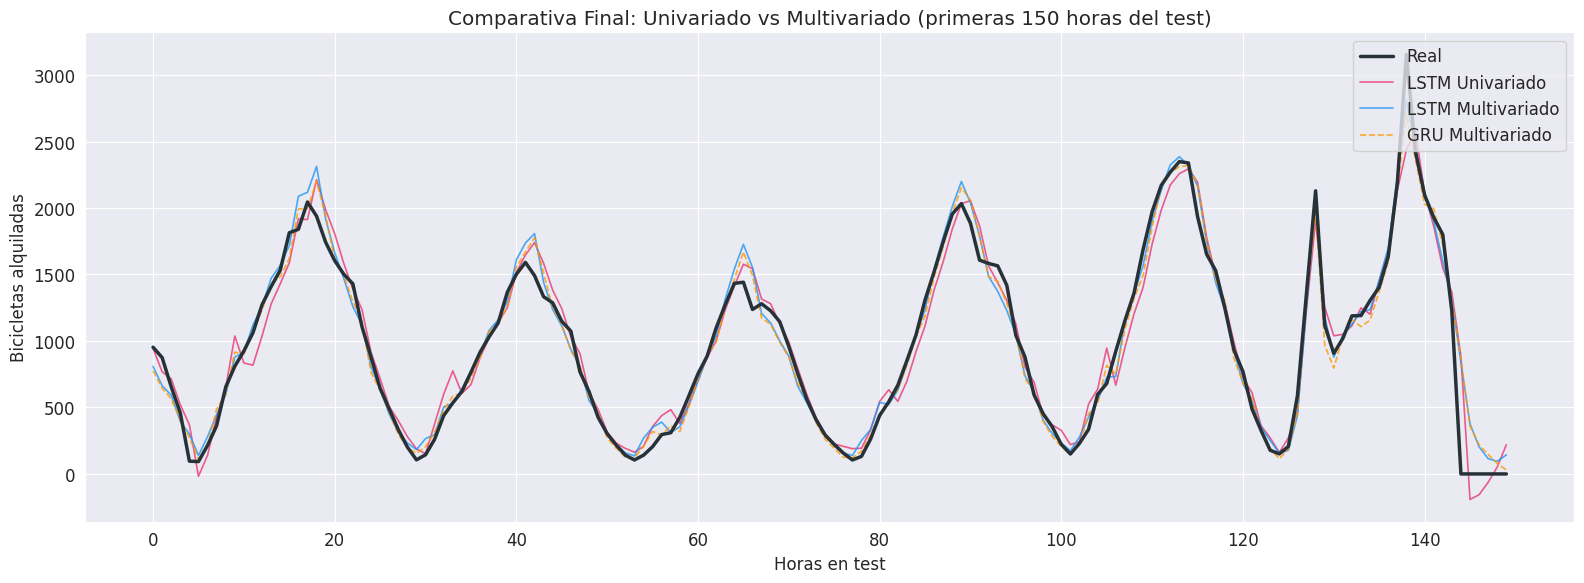

In [ ]:
# ============================================================
# 📊 Visualización final comparativa
# ============================================================
fig, ax = plt.subplots(figsize=(16, 6))

n_show = 150
ax.plot(y_test_real_m[:n_show], color=COLORS['actual'],
        linewidth=2.5, label='Real', zorder=5)
ax.plot(pred_uni_real[:n_show], color=COLORS['pred'],
        linewidth=1.2, alpha=0.7, label='LSTM Univariado')
ax.plot(pred_lstm_real[:n_show], color=COLORS['lstm'],
        linewidth=1.2, alpha=0.8, label='LSTM Multivariado')
ax.plot(pred_gru_real[:n_show], color=COLORS['gru'],
        linewidth=1.2, alpha=0.8, label='GRU Multivariado', linestyle='--')

ax.set_xlabel('Horas en test')
ax.set_ylabel('Bicicletas alquiladas')
ax.set_title('Comparativa Final: Univariado vs Multivariado (primeras 150 horas del test)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 💡 Resultados y conclusiones del Ejercicio 2

**Comparación en el test cronológico (1,680 horas):**

| Modelo | MAE (bicis) | RMSE (bicis) | Parámetros | Tiempo (s) |
|---|---|---|---|---|
| Naive (t-1 h) | 194.8 | 302.1 | — | — |
| Naive estacional (t-24 h) | 392.7 | 656.9 | — | — |
| LSTM univariado (64 unidades) | 117.7 | 176.7 | 16,961 | 45.2 |
| LSTM stacked multivariado | 97.0 | **139.7** | 122,177 | 69.2 |
| **GRU stacked multivariado** | **96.3** | 144.4 | 92,737 | 66.5 |

**Experimento de ventana (GRU de 64 unidades, evaluado sobre las mismas 1,584 horas):**

| Ventana | MAE (bicis) | Tiempo (s) | Parámetros |
|---|---|---|---|
| 24 h (1 día) | 150.4 | 26.1 | 14,465 |
| **72 h (3 días)** | **141.1** | 31.0 | 14,465 |
| 168 h (7 días) | 144.1 | 39.1 | 14,465 |

**Conclusiones:**

1. **GRU vs LSTM: rendimiento equivalente con menos costo.** La GRU tuvo 24.1 % menos parámetros (92,737 vs 122,177) y obtuvo el menor MAE (96.3 vs 97.0), pero el LSTM obtuvo el menor RMSE (139.7 vs 144.4) y la menor pérdida de validación (0.001617 vs 0.001687). Las diferencias son menores a 1 bicicleta de MAE y la GRU solo fue ≈4 % más rápida (66.5 s vs 69.2 s); con una sola ejecución y una sola semilla no se puede declarar un ganador. Lo que sí se sostiene es que la GRU ofrece prácticamente el mismo error con un modelo más ligero.
2. **El enfoque multivariado sí mejoró al univariado.** Las variables climáticas y de calendario redujeron el MAE un 17.6 % (LSTM) y un 18.2 % (GRU) frente al LSTM univariado (117.7), y el RMSE un 20.9 % y 18.3 %. Coherente con la matriz de correlación, donde, entre las variables usadas como entrada, la temperatura es la más asociada con la demanda (+0.539), seguida de la radiación solar (+0.262); la lluvia se asocia de forma negativa (−0.123). Este experimento compara el modelo univariado simple con los modelos apilados y con más variables; no aísla el aporte de cada variable por separado.
3. **Todos los modelos recurrentes superan a los baselines.** El mejor modelo (GRU multivariado) redujo el MAE un 50.6 % frente al naive y un 75.5 % frente al naive estacional. Como en el Ejercicio 1, el naive estacional (t-24 h) fue el peor baseline a este horizonte de 1 hora. Con un MAE de ≈96 bicis, el error equivale a ≈14 % de la demanda media anual (705 bicis/hora).
4. **El tamaño de ventana importa, con un óptimo en 72 horas.** La ventana de 3 días obtuvo el menor MAE (141.1); la de 1 día fue 6.6 % peor (pierde el contexto del patrón de días previos) y la de 7 días fue 2.2 % peor, con 26 % más de tiempo de entrenamiento (posiblemente por más ruido y más riesgo de sobreajuste con solo ~7,000 ventanas). El número de parámetros no cambia con la ventana porque los pesos recurrentes se comparten en el tiempo. Estos MAE no son comparables con la tabla principal (aquí se usó una sola capa GRU de 64 unidades, menos épocas y 1,584 horas de test), aunque la diferencia con los modelos apilados (≈96 bicis) sugiere que la arquitectura apilada aportó más que el ajuste de la ventana.
5. **No se observó degradación por desfase estacional.** Aunque el test corresponde a octubre y noviembre, meses ausentes en entrenamiento, el error no empeoró respecto a la validación: el RMSE de validación equivalente fue ≈143 bicis (LSTM) y ≈146 (GRU), frente a 139.7 y 144.4 en test. Aun así, un solo año de datos limita la generalización a otras estaciones y años.
6. **Limitación en las horas fuera de servicio (`Functioning Day = No`).** Son 295 horas (3.4 % del dataset) con demanda 0. En las primeras 150 horas del test, donde el servicio se interrumpe, ningún modelo anticipa la caída brusca a 0: reaccionan con retraso, y el LSTM univariado llegó a predecir valores negativos (≈ -200 bicis). La bandera `functioning_flag` solo informa de las horas pasadas de la ventana, no de la hora a predecir, por lo que no permite anticipar un cierre. Estas horas no se evaluaron por separado, y pueden elevar el MAE/RMSE; una mejora posible es acotar las predicciones a ≥ 0 y excluir o tratar aparte esos días.

---

## ✅ Checklist de Verificación — Series de Tiempo con Deep Learning

| # | Verificación | Estado |
|---|---|---|
| 1 | Serie regular: ordenada, sin timestamps duplicados ni huecos | ✅ |
| 2 | Split cronológico (nunca aleatorio para forecasting) | ✅ |
| 3 | Normalización con `fit` solo en datos de entrenamiento | ✅ |
| 4 | Ventanas deslizantes con función `create_sequences` reproducible | ✅ |
| 5 | Shapes correctos: `(samples, timesteps, features)` | ✅ |
| 6 | Baselines calculados antes de evaluar el modelo (naive y naive estacional) | ✅ |
| 7 | EarlyStopping + ReduceLROnPlateau para evitar sobreajuste | ✅ |
| 8 | Métricas apropiadas para forecasting: MAE/RMSE (MAPE con cuidado si hay ceros) | ✅ |
| 9 | Dropout entre capas recurrentes apiladas | ✅ |
| 10 | Desnormalización antes de calcular métricas interpretables | ✅ |
| 11 | Variables cíclicas (hora del día) codificadas con seno/coseno | ✅ |
| 12 | Comparación justa entre ventanas (mismos targets de evaluación) | ✅ |
| 13 | Visualización de predicciones vs valores reales | ✅ |

## 📋 Resumen de Ejercicios — Sesión 10-A

| Ejercicio | Nivel | Tarea | Arquitectura | Dataset | Resultado principal |
|---|---|---|---|---|---|
| 1 | 🟢 Básico | Forecasting univariado | LSTM simple (16,961 parámetros) | PJM Hourly Energy Consumption (PJME, MW) | MAE 344.2 MW (MAPE 1.12 %): 67.8 % mejor que el naive y 84.2 % mejor que el naive estacional |
| 2 | 🟡 Intermedio | Forecasting multivariado | LSTM vs GRU stacked | Seoul Bike Sharing Demand (9 variables) | GRU MAE 96.3 y LSTM 97.0 bicis (≈18 % mejor que el univariado, 117.7); GRU con 24.1 % menos parámetros; mejor ventana: 72 h |

**Lecciones transversales (respaldadas por los resultados):**
- La preparación de datos (limpieza, split cronológico, normalización solo con train, ventanas) fue la base de ambos experimentos: sin ella las ventanas habrían mezclado horas no consecutivas y habría fuga de datos temporal.
- Un buen baseline es el primer filtro, y hay que elegirlo bien: a horizonte de 1 hora el naive simple (t-1 h) fue más fuerte que el naive estacional (t-24 h) en los dos datasets (MAE 1,070 vs 2,183 MW; 195 vs 393 bicis). Los modelos recurrentes superaron a ambos.
- Agregar variables explicativas útiles (clima y hora codificada de forma cíclica) redujo el error cerca de 18 % en Seúl.
- La GRU es un excelente punto de partida por su balance rendimiento/eficiencia: igualó el error del LSTM con 24.1 % menos parámetros.
- El tamaño de ventana tiene un óptimo (3 días en la demanda de bicicletas); más contexto no siempre es mejor.
- Los resultados provienen de una sola ejecución con semilla 42; las diferencias pequeñas (como GRU vs LSTM) no son concluyentes.